# ML1 - GridSearch with DecisionTreeRegressor, RandomForestRegressor

This notebook follows the ML1_Pipeline_Model notebook and focuses on:
1. Using DecisionTreeRegressor and RandomForestRegressor (or others)  
2. Hyperparameter tuning with GridSearchCV  
3. Cross-validation

## 1. Importing Libraries

In [35]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso 
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.tree import DecisionTreeRegressor, export_text
from scipy.stats import uniform
from scipy.stats import randint
from tabicl import TabICLRegressor


## 2. Loading and Preparing Data with the Pipeline

We follow the same preparation steps as in the previous notebook.


In [36]:
# Load the data from the pickle file.
#df = pd.read_pickle('arbres_clean_Laura.pkl')

#df.to_csv('arbres_clean_Laura.csv', index=False)

df = pd.read_csv('arbres_clean_Laura.csv')
#df = pd.read_csv('arbres_clean_Alexia.csv')

#Prepare the train and test sets
X = df.drop(columns=['anneedeplantation'])
y = df['anneedeplantation']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=20)

categorical_variables = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numerical_variables = X_train.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)

#pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)])
	
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

['sous_categorie', 'genre_bota', 'espece', 'portarbre', 'structure'] ['adr_secteur', 'stadededeveloppement', 'hauteurarbre', 'latitude', 'longitude']


In [37]:
#permet de savoir combien de variables on a après le pipeline, ici 421 colonnes
X_train_transformed.shape

(22144, 411)

In [38]:
categorical_pipeline_icl = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor_icl = ColumnTransformer([
    ('cat', categorical_pipeline_icl, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)
])

## 3. Initial Cross-Validation

Before tuning hyperparameters, let's evaluate a model with default parameters using cross-validation.


In [39]:
# Initial cross-validation without hyperparameter tuning  
# We can also print the MSE or MAE scores from each cross-validation fold.

model_linear = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])
model_lasso = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', Lasso(alpha=0.001, max_iter=10000))
])

#max_depth est plus ou moins nb de variables explorées
model_random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(max_depth=450, min_samples_leaf=0.001,random_state=5029))
])

model_random_forest_default = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(random_state=5029))
])

model_random_forest_RS = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', RandomForestRegressor(max_depth=450, min_samples_leaf=0.001,
                                       n_estimators=70, random_state=5029))
])

model_decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', DecisionTreeRegressor(max_depth=400, min_samples_leaf=0.001, random_state=5029))
])

model_gradient_boosting_regressor = Pipeline([
    ('preprocessor', preprocessor),
    ('regression', GradientBoostingRegressor(random_state=5029))
])

model_tabicl = Pipeline([
    ('preprocessor', preprocessor_icl),
    ('regression', TabICLRegressor())
])




In [31]:
#application avec la régression linéaire de base
arbres_scores = cross_val_score(model_linear, X_train, y_train, cv = 5, scoring='neg_mean_squared_error') 

print("MSE moyen :", np.mean(-arbres_scores))
print("Écart-type :", np.std(-arbres_scores))

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/sabrina/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/sabrina/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/Users/sabrina/opt/anaconda3/lib/python3.9/site-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "/Users/sabrina/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *arg

## 4. 🌳 Modeling with GridSearchCV

Let's choose two machine learning models.

Evaluate the models with hyperparameter tuning (testing different hyperparameter values).  
Optimize the models as you wish, for example for Decision Tree and Random Forest:

### 🔍 Hyperparameters Tested
- `max_depth`: maximum depth of the trees [3, 4, 5, 10]  
- `min_samples_leaf`: minimum number of samples required at a leaf [0.1, 0.05]  
- `n_estimators` (for Random Forest only): number of trees in the forest [50, 100, 200]

Let's use GridSearchCV to automate the search for the best hyperparameters.

In [7]:
# Hyperparameter tuning with GridSearchCV, and we can print the MSE or MAE scores for each cross-validation fold.

param_grid = [
 {'regression__alpha': [0.001, 0.01, 0.1, 1, 3, 10, 100, 1000]}
 ]

#arbres_scores_lasso = cross_val_score(model_lasso, X_train, y_train, cv = 5, scoring='neg_mean_squared_error')
arbres_grid_search = GridSearchCV(model_lasso, param_grid, cv=5, scoring='neg_mean_squared_error')
arbres_grid_search.fit(X_train, y_train)

arbres_grid_results = pd.DataFrame(arbres_grid_search.cv_results_)

print(arbres_grid_results)
print(arbres_grid_search.best_estimator_)



KeyboardInterrupt: 

In [75]:
#GridSearch avec la random forest
param_grid_forest = {
    'regression__max_depth': [400],
    'regression__min_samples_leaf': [0.05, 0.01, 0.001, 0.0001],
    'regression__n_estimators': [250, 300, 350, 400]
}

arbres_RF_grid_search = GridSearchCV(model_random_forest, param_grid_forest, cv=5, scoring='neg_mean_squared_error')
arbres_RF_grid_search.fit(X_train, y_train)

arbres_RF_grid_results = pd.DataFrame(arbres_RF_grid_search.cv_results_)

KeyboardInterrupt: 

In [43]:
print(arbres_RF_grid_results)
print(arbres_RF_grid_search.best_estimator_)

    mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0        0.645341      0.013416         0.028931        0.001230   
1        1.213884      0.006814         0.039056        0.001071   
2        2.673382      0.341543         0.062526        0.002476   
3        0.837435      0.013377         0.028416        0.000674   
4        1.595760      0.022959         0.039442        0.000758   
5        3.430156      0.137859         0.070770        0.012306   
6        0.812269      0.069100         0.031757        0.002043   
7        1.474086      0.056844         0.045016        0.007823   
8        2.815541      0.112233         0.064135        0.002377   
9        1.098131      0.118489         0.030494        0.001874   
10       1.979935      0.142282         0.041990        0.000754   
11       3.946953      0.126347         0.070238        0.003012   
12       0.835606      0.082736         0.032589        0.002581   
13       1.464827      0.105739         0.041021

In [84]:
#Plutôt que d'utiliser un gridsearch, plutôt utiliser un randomsearch, plus rapide


#RandomizedSearchCV avec la random forest

distributions = {
    'regression__max_depth': [3, 4, 5, 10, None],
    'regression__min_samples_leaf': [0.05, 0.1],
    'regression__n_estimators': randint(50, 201)
}

arbres_RF_random_search = RandomizedSearchCV(
    model_random_forest_RS,
    param_distributions=distributions,
    n_iter=10,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

arbres_RF_random_search.fit(X_train, y_train)

arbres_RF_random_results = pd.DataFrame(arbres_RF_random_search.cv_results_)

print(arbres_RF_random_results)
print(arbres_RF_random_search.best_estimator_)


   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0       2.577013      0.035323         0.074117        0.008281   
1       1.879092      0.020088         0.087066        0.026265   
2       4.615553      0.051118         0.110851        0.005592   
3       4.620794      0.057981         0.120674        0.007965   
4       4.874317      0.053671         0.120534        0.002757   
5       3.635170      0.038563         0.100709        0.003128   
6       2.326952      0.019736         0.080739        0.003120   
7       1.912873      0.016433         0.071648        0.002199   
8       2.459869      0.020712         0.079383        0.008488   
9       3.028669      0.193310         0.060939        0.008183   

  param_regression__max_depth  param_regression__min_samples_leaf  \
0                          10                                0.05   
1                           5                                0.10   
2                           4                          

In [ ]:
#RandomizedSearchCV avec le gradient boosting

distributions = {
    'regression__max_depth': [3, 4, 5, 10, None],
    'regression__min_samples_leaf': [0.05, 0.1],
    'regression__n_estimators': randint(50, 201)
}

arbres_RF_random_search = RandomizedSearchCV(
    model_random_forest_RS,
    param_distributions=distributions,
    n_iter=10,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

arbres_RF_random_search.fit(X_train, y_train)

arbres_RF_random_results = pd.DataFrame(arbres_RF_random_search.cv_results_)

print(arbres_RF_random_results)
print(arbres_RF_random_search.best_estimator_)


In [8]:
# Code for evaluating the best model on the test set.

# Créer un modèle de référence
dummy = DummyRegressor(strategy='mean')

# L'entraîner sur les données d'entraînement
dummy.fit(X_train_transformed, y_train)

# Prédire les années sur le test
y_pred_dummy = dummy.predict(X_test)

dummy_scores = cross_val_score(
    dummy,
    X_train_transformed,
    y_train,
    cv=10,
    scoring='neg_mean_squared_error'
)



## 5. Final Evaluation on the Test Set

In [40]:

from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

scoring = {
    'mse': 'neg_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

models = {
    'LinearRegression': model_linear,
    'Lasso': model_lasso,
    'Dummy': dummy,
    'Random Forest': model_random_forest_default,
    'Decision Tree': model_decision_tree,
    'Gradient Boosting': model_gradient_boosting_regressor,
    #'ICL': model_tabicl
}

resultats = []
predictions = {}

for name, model in models.items():

    # 1. Validation croisée sur le train
    scores = cross_validate(
        model, X_train, y_train,
        cv=5, scoring=scoring
    )

    mse_cv = -scores['test_mse']
    mae_cv = -scores['test_mae']
    r2_cv = scores['test_r2']
    rmse_cv = np.sqrt(mse_cv)

    # 2. Entraînement sur tout le train
    model.fit(X_train, y_train)

    # 3. Prédictions sur train et test
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Sauvegarder les prédictions de chaque modèle
    predictions[name] = y_pred_test

    # 4. Métriques train
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    mae_train = mean_absolute_error(y_train, y_pred_train)
    r2_train = r2_score(y_train, y_pred_train)

    # 5. Métriques test
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    mae_test = mean_absolute_error(y_test, y_pred_test)
    r2_test = r2_score(y_test, y_pred_test)

    # 6. Affichage détaillé par modèle
    print(f"\n{'=' * 65}")
    print(f"MODÈLE : {name}")
    print(f"{'=' * 65}")
    print(f"{'Métrique':<12} {'TRAIN':>12} {'CV (moy.)':>12} {'TEST':>12}")
    print("-" * 53)
    print(f"{'RMSE':<12} {rmse_train:>12.2f} {rmse_cv.mean():>12.2f} {rmse_test:>12.2f}")
    print(f"{'MAE':<12} {mae_train:>12.2f} {mae_cv.mean():>12.2f} {mae_test:>12.2f}")
    print(f"{'R²':<12} {r2_train:>12.3f} {r2_cv.mean():>12.3f} {r2_test:>12.3f}")
    print(f"\nÉcart-type MAE (CV) : {mae_cv.std():.2f}")
    print(f"Écart RMSE test - train : {rmse_test - rmse_train:+.2f}")
    print(f"RMSE CV : {rmse_cv.mean():.2f} ± {rmse_cv.std():.2f}")

    # 7. Sauvegarde des résultats
    resultats.append({
        'Modèle': name,
        'RMSE train': rmse_train,
        'RMSE CV': rmse_cv.mean(),
        'RMSE test': rmse_test,
        'MAE train': mae_train,
        'MAE CV': mae_cv.mean(),
        'MAE test': mae_test,
        'R² train': r2_train,
        'R² CV': r2_cv.mean(),
        'R² test': r2_test,
        'Écart-type MAE CV': mae_cv.std()
    })

# 8. Tableau comparatif de tous les modèles
df_resultats = pd.DataFrame(resultats)

display(
    df_resultats
    .sort_values('RMSE CV')
    .round(2)
)



MODÈLE : LinearRegression
Métrique            TRAIN    CV (moy.)         TEST
-----------------------------------------------------
RMSE                11.70        11.93        12.27
MAE                  8.84         9.02         9.18
R²                  0.584        0.566        0.551

Écart-type MAE (CV) : 0.13
Écart RMSE test - train : +0.58
RMSE CV : 11.93 ± 0.24

MODÈLE : Lasso
Métrique            TRAIN    CV (moy.)         TEST
-----------------------------------------------------
RMSE                11.75        11.90        12.22
MAE                  8.93         9.04         9.22
R²                  0.580        0.569        0.555

Écart-type MAE (CV) : 0.13
Écart RMSE test - train : +0.47
RMSE CV : 11.90 ± 0.24

MODÈLE : Dummy
Métrique            TRAIN    CV (moy.)         TEST
-----------------------------------------------------
RMSE                18.12        18.13        18.32
MAE                 15.90        15.90        15.94
R²                  0.000       -0.000   

,Modèle,RMSE train,RMSE CV,RMSE test,MAE train,MAE CV,MAE test,R² train,R² CV,R² test,Écart-type MAE CV
3,Random Forest,2.55,7.17,6.69,1.03,3.06,2.74,0.98,0.84,0.87,0.10
4,Decision Tree,8.87,10.03,10.13,5.23,5.90,6.02,0.76,0.69,0.69,0.13
5,Gradient Boosting,11.41,11.56,11.75,8.93,9.03,9.17,0.60,0.59,0.59,0.09
1,Lasso,11.75,11.90,12.22,8.93,9.04,9.22,0.58,0.57,0.55,0.13
0,LinearRegression,11.70,11.93,12.27,8.84,9.02,9.18,0.58,0.57,0.55,0.13
2,Dummy,18.12,18.13,18.32,15.90,15.90,15.94,0.00,-0.00,-0.00,0.11


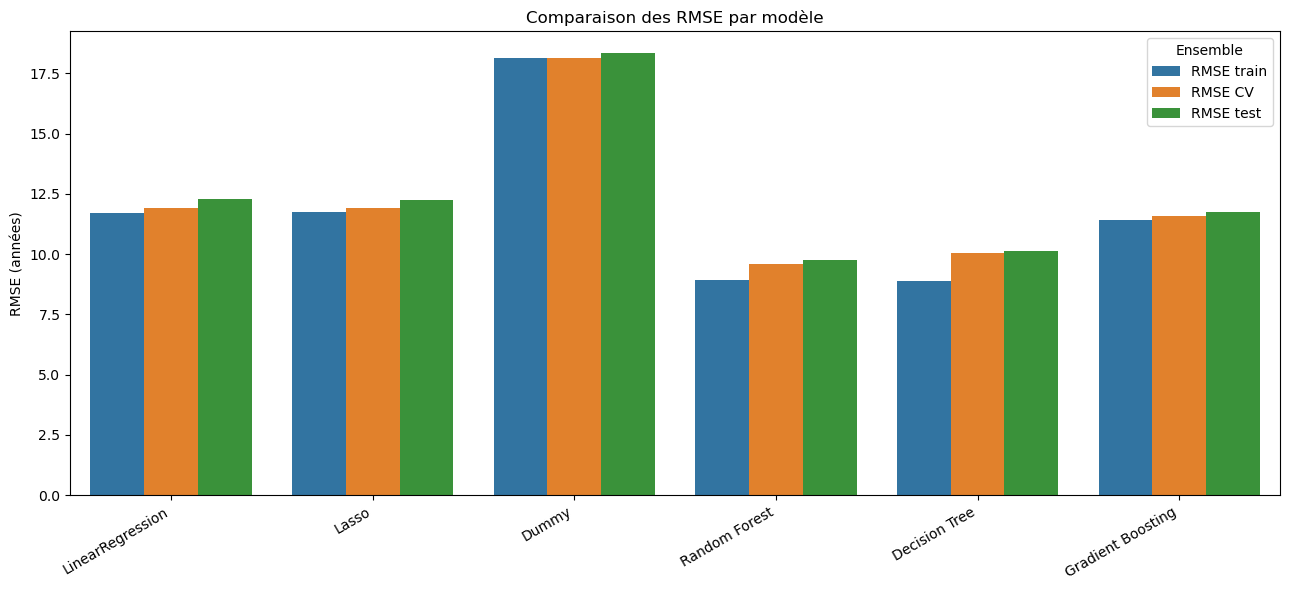

In [10]:
# Transformer les résultats au format adapté à Seaborn
df_rmse = df_resultats.melt(
    id_vars='Modèle',
    value_vars=['RMSE train', 'RMSE CV', 'RMSE test'],
    var_name='Ensemble',
    value_name='RMSE'
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=df_rmse,
    x='Modèle',
    y='RMSE',
    hue='Ensemble'
)

plt.title('Comparaison des RMSE par modèle')
plt.ylabel('RMSE (années)')
plt.xlabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

## 6. Visualization of Predictions  
One model will suffice.

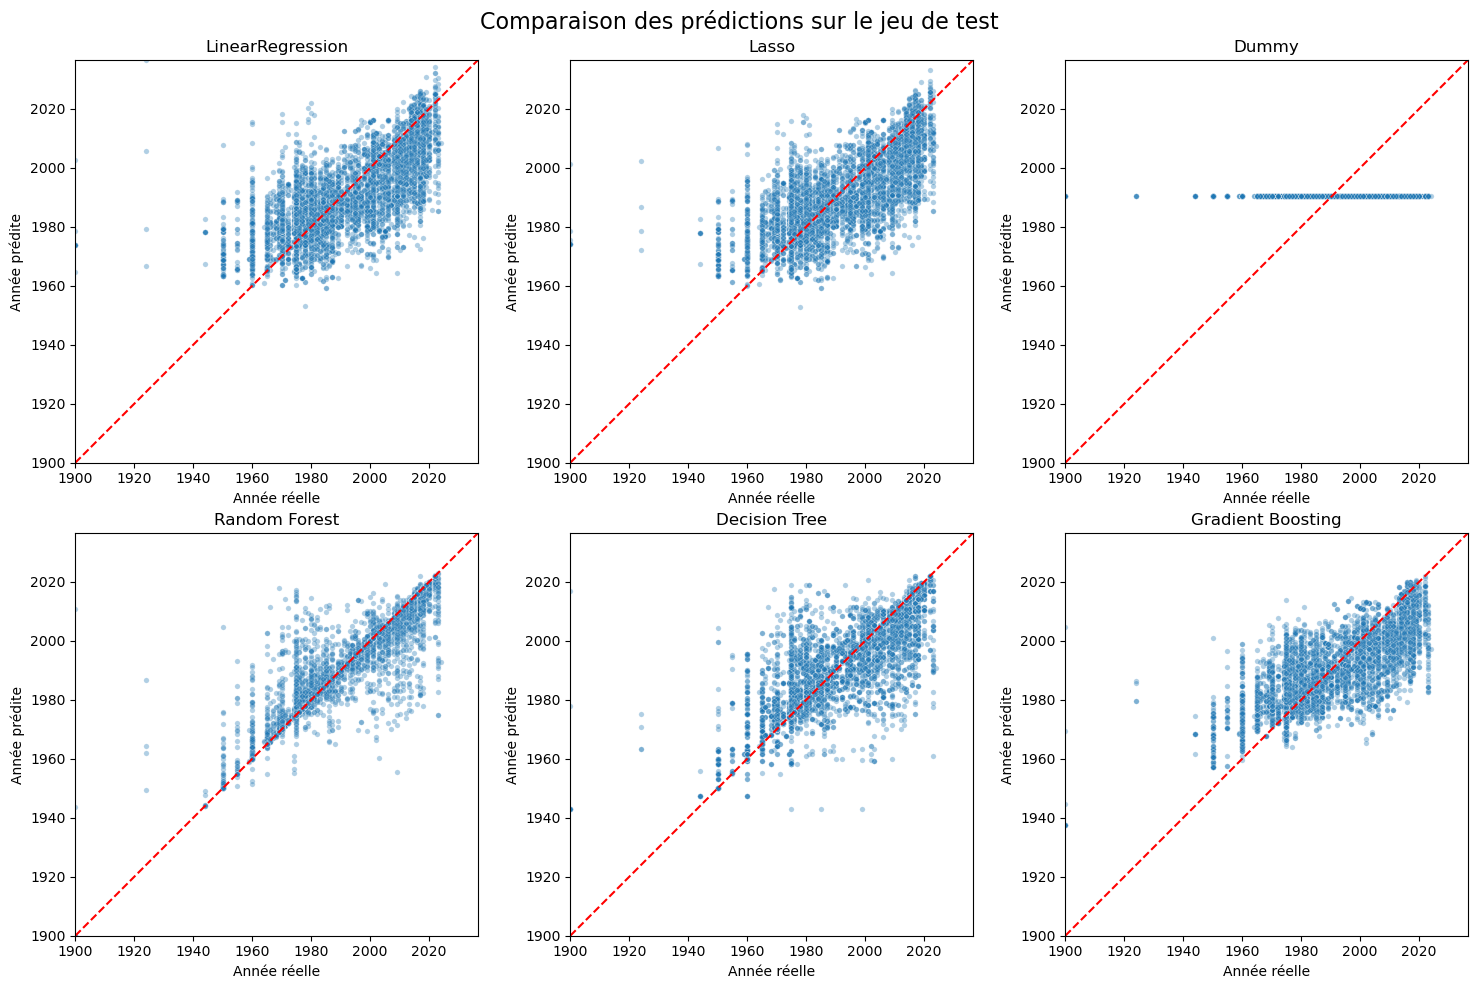

In [41]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Même échelle pour tous les graphiques
lim_min = min(
    y_test.min(),
    min(np.min(pred) for pred in predictions.values())
)

lim_max = max(
    y_test.max(),
    max(np.max(pred) for pred in predictions.values())
)

# Grille de graphiques
n_models = len(predictions)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 5 * n_rows)
)

axes = np.array(axes).flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):

    sns.scatterplot(
        x=y_test,
        y=y_pred,
        alpha=0.35,
        s=15,
        ax=ax
    )

    # Prédiction parfaite : y = x
    ax.plot(
        [lim_min, lim_max],
        [lim_min, lim_max],
        'r--'
    )

    ax.set_title(name)
    ax.set_xlabel("Année réelle")
    ax.set_ylabel("Année prédite")
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_aspect('equal', adjustable='box')

# Masquer les graphiques inutilisés
for ax in axes[n_models:]:
    ax.set_visible(False)

plt.suptitle(
    "Comparaison des prédictions sur le jeu de test",
    fontsize=16
)

plt.tight_layout()
plt.show()


## [OPTIONAL] 7.Feature Importance

Using the random forest, how can we determine which features are the most important?

In [48]:
# Code. In your opinion, how is feature importance calculated in Random Forest?

In [34]:

import numpy as np
import pandas as pd
from sklearn.neighbors import BallTree

df_arbres = pd.read_csv('../arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')

# On suppose que df possède les colonnes :
# latitude, longitude, anneedeplantation

# Conversion des coordonnées en radians
coordonnees = np.radians(
    df[['latitude', 'longitude']].to_numpy()
)

# Construction de l'arbre spatial
tree = BallTree(coordonnees, metric='haversine')

# Rayon de recherche : 50 mètres
rayon_terre = 6371000  # mètres
rayon = 50 / rayon_terre

# Recherche des voisins pour chaque arbre
indices_voisins = tree.query_radius(
    coordonnees,
    r=rayon
)

# Années de plantation
annees = df_arbres['anneedeplantation'].to_numpy()

moyennes = []

for i, voisins in enumerate(indices_voisins):

    # Exclure l'arbre lui-même
    voisins = voisins[voisins != i]

    # Années connues des arbres voisins
    annees_voisins = annees[voisins]
    annees_voisins = annees_voisins[
        ~pd.isna(annees_voisins)
    ]

    if len(annees_voisins) > 0:
        moyennes.append(np.mean(annees_voisins))
    else:
        moyennes.append(np.nan)

# Ajout de la nouvelle colonne
df['annee_moyenne_voisins_50m'] = moyennes


ValueError: Input contains NaN.

Typically, one might consider using backward elimination on feature importance to select the best subset of features, but this can be time-consuming if there are many features and the model takes a while to train, as is the case here. Instead, we can use Lasso-regularized regression to eliminate features, before retraining a RandomForest on the selected features. Create a pipeline with `LassoCV` as the selector and a RandomForest as the model with the best hyperparameters found by the previous grid-search. Evaluate on the test set.

In [49]:
# Code

## 8. [OPTIONAL]  Compare more different models

Compare more regression models with one another (for example, in addition to linear regression, decision trees, and forests, use `GradientBoostingRegressor`, and the novel `TabICLRegressor` if you have time ( https://github.com/soda-inria/tabicl ))), by performing appropriate hyperparameter tuning for each model:

In [50]:
# Code. Search which hyper-parameters are worth tuning for each model

Choose the model that performs best and its optimal hyperparameters, then select the best subset of features for this model, and finally perform one last grid search on your model’s hyperparameters using the selected features to obtain your final model. Evaluate it on the test set.

In [51]:
# Code

## Conclusion